# 03 — Methods, model selection and validation

This notebook is a thin driver around `src/modelling.py`. It

1. runs the rolling-year validation for every cohort × training scope × feature set × model × setting,
2. compares the models with the two baselines (random selection and EA's *potential − overall* ranking),
3. answers the project's comparisons on **validation years only**: with vs without EA potential, rating-only vs
   rating + match history, and (young cohort) training on all players vs young players only,
4. refits the best setting of each candidate on 2009–2013 and writes 2014 **scores** for the evaluation notebook.

No 2014 metric is computed or shown here: the test year is evaluated once, in `04_evaluation_explanations.ipynb`.
Decisions are logged in `docs/decisions/03_modelling.md`. The whole notebook takes about 3 minutes on a 24-core laptop.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))
import json, time
import pandas as pd
from src import modelling as M
from src.common import B_FIGURES, PREDICTIONS, VALIDATION_YEARS, save, set_style
from src.features import FEATURE_SETS, load_feature_table
set_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
pd.Series({k: len(v) for k, v in FEATURE_SETS.items()}, name="n_columns").to_frame()

,n_columns
ea_gap_only,1
rating_no_potential,44
rating_only,47
combined,58


## 1. Validation design

* **Unit:** one player in one year; on 1 August of year *y* we rank that year's cohort and a scout watches the top
  `floor(10%)`. Primary metric **Precision@10%** (share of the watch-list that breaks out), computed **within each year**
  because breakout prevalence drifts from 26% (2009) to 11% (2013). Also Recall@10% and average precision (PR-AUC).
* **Rolling (expanding-window) folds:** train on all cohort years before the validation year — 2009–10 → 2011,
  2009–11 → 2012, 2009–12 → 2013. A row of year *y* has its label on 1 Aug *y+1*, so it is available when predicting
  *y+1*: no future information enters a fold. The same player can recur across years; training rows always come from
  earlier years than the validation rows, so a validation prediction never sees that player's own outcome.
* **Preprocessing inside the pipeline:** median imputation, scaling (logistic regression only), one-hot league/position
  and optional PCA on the 33 skills are fitted on each fold's training rows only.
* **Selection rule:** for each candidate the mean Precision@10% over the three folds; ties broken by mean average precision.
* **Cohorts / scopes:** `all` (trained on all players) and `young` (age ≤ 24 on 1 Aug), the latter trained either on
  all players or on young players only. A model trained on all players scores everyone, so its young-cohort score is
  simply its ranking restricted to young players.

In [2]:
df = load_feature_table()
folds = pd.DataFrame([{"validation_year": y, "train_years": f"2009-{y-1}",
                       "train_rows_all": int((df.year < y).sum()), "train_rows_young": int(((df.year < y) & (df.age <= 24)).sum()),
                       "valid_rows_all": int((df.year == y).sum()), "valid_rows_young": int(((df.year == y) & (df.age <= 24)).sum()),
                       "breakout_rate_all": round(df[df.year == y].breakout.mean(), 3)} for y in VALIDATION_YEARS])
folds

,validation_year,train_years,train_rows_all,train_rows_young,valid_rows_all,valid_rows_young,breakout_rate_all
0,2011,2009-2010,6852,2528,3618,1403,0.201
1,2012,2009-2011,10470,3931,3741,1449,0.182
2,2013,2009-2012,14211,5380,3791,1420,0.113


## 2. Methods and hyperparameter grids

* **Logistic regression** — interpretable linear reference. L2 strength `C` ∈ {0.01, 0.1, 1}; optional PCA on the
  33 highly correlated skills (3, 5 or 10 components; the proposal's dimension-reduction idea); scaled inputs.
* **Random forest** — non-linear, robust to unscaled and correlated inputs. 300 trees (more trees only lower variance);
  leaf size {5, 25} and features per split {√p, 0.33p} control over-fitting.
* **Gradient boosting** (`HistGradientBoostingClassifier`) — usually strongest on tabular data. 300 iterations,
  learning rate {0.01, 0.03, 0.1} × max leaves {3, 7, 31}, `min_samples_leaf=40`, L2 = 1, no early stopping
  (its internal random split would ignore time order).
* **Class weighting** (none vs balanced) in every family, since prevalence is 11–26%.

The grids are deliberately small: with three folds, a Precision@10% on ~140–380 watched players has a sampling
error of roughly 2.5–4 percentage points per year, so finer grids would mostly fit noise. The boosting and PCA grids
were widened once after a first run whose optima sat on the grid edge.

In [3]:
print({m: len(M.grid(m, "combined")) for m in M.GRIDS}, "settings per family on 'combined'")
M.GRIDS

{'logreg': 24, 'random_forest': 8, 'hist_gb': 18} settings per family on 'combined'


{'logreg': {'C': [0.01, 0.1, 1.0],
  'class_weight': [None, 'balanced'],
  'pca_skills': [None, 3, 5, 10]},
 'random_forest': {'min_samples_leaf': [5, 25],
  'max_features': ['sqrt', 0.33],
  'class_weight': [None, 'balanced_subsample']},
 'hist_gb': {'learning_rate': [0.01, 0.03, 0.1],
  'max_leaf_nodes': [3, 7, 31],
  'class_weight': [None, 'balanced']}}

## 3. Run selection, final refit and test-year scoring (≈ 2.5 min)

In [4]:
t0 = time.time()
selected = M.main()
print(f"total {time.time() - t0:.0f}s")
scores, summary, best = M.load_outputs()

validating 182 candidates x 3 folds x 2 training scopes


window check: keep expanding window (2009-2013 refit)


total 123s


## 4. Validation results vs baselines

Best setting per (training scope, model, feature set), in percent. `ea_gap` ranks by EA's potential − overall;
`random` is the expected precision of a random watch-list (the year's prevalence).

In [5]:
M.comparison_table(best, summary, "all").drop(columns="setting")

,train_scope,model,feature_set,p10_2011,p10_2012,p10_2013,mean_p10,sd_p10,mean_recall,mean_ap
0,all,logreg,combined,69.3,61.2,43.3,57.9,13.3,35.3,50.7
1,all,hist_gb,combined,67.9,59.1,43.3,56.7,12.5,34.7,47.7
2,all,random_forest,combined,67.3,57.5,42.5,55.8,12.5,34.1,47.7
3,all,logreg,rating_only,64.3,52.7,42.0,53.0,11.2,32.6,44.3
4,all,logreg,rating_no_potential,64.5,53.2,40.6,52.8,12.0,32.3,43.9
5,all,random_forest,rating_only,64.0,50.3,42.5,52.2,10.9,32.2,43.5
6,all,hist_gb,rating_only,64.0,49.7,41.2,51.6,11.5,31.7,42.5
7,all,hist_gb,rating_no_potential,63.4,50.0,40.9,51.4,11.3,31.6,42.0
8,all,random_forest,rating_no_potential,63.7,48.4,40.9,51.0,11.6,31.4,43.0
9,all,hist_gb,ea_gap_only,44.3,43.3,36.1,41.3,4.5,25.9,34.2


In [6]:
M.comparison_table(best, summary, "young").drop(columns="setting")

,train_scope,model,feature_set,p10_2011,p10_2012,p10_2013,mean_p10,sd_p10,mean_recall,mean_ap
0,young,hist_gb,combined,83.6,70.8,56.3,70.2,13.6,25.2,56.0
1,all,logreg,combined,81.4,72.9,55.6,70.0,13.1,25.1,58.0
2,young,logreg,combined,82.9,70.1,55.6,69.5,13.6,24.9,57.2
3,all,hist_gb,combined,80.7,75.0,52.1,69.3,15.1,24.7,55.8
4,young,random_forest,combined,80.0,70.1,56.3,68.8,11.9,24.8,55.2
5,all,random_forest,combined,81.4,70.8,53.5,68.6,14.1,24.5,55.4
6,all,hist_gb,rating_only,78.6,66.7,49.3,64.8,14.7,23.1,50.0
7,all,logreg,rating_only,77.1,63.2,52.8,64.4,12.2,23.1,51.6
8,all,hist_gb,rating_no_potential,74.3,69.4,49.3,64.3,13.3,23.0,49.1
9,all,logreg,rating_no_potential,78.6,61.8,51.4,63.9,13.7,22.9,51.1


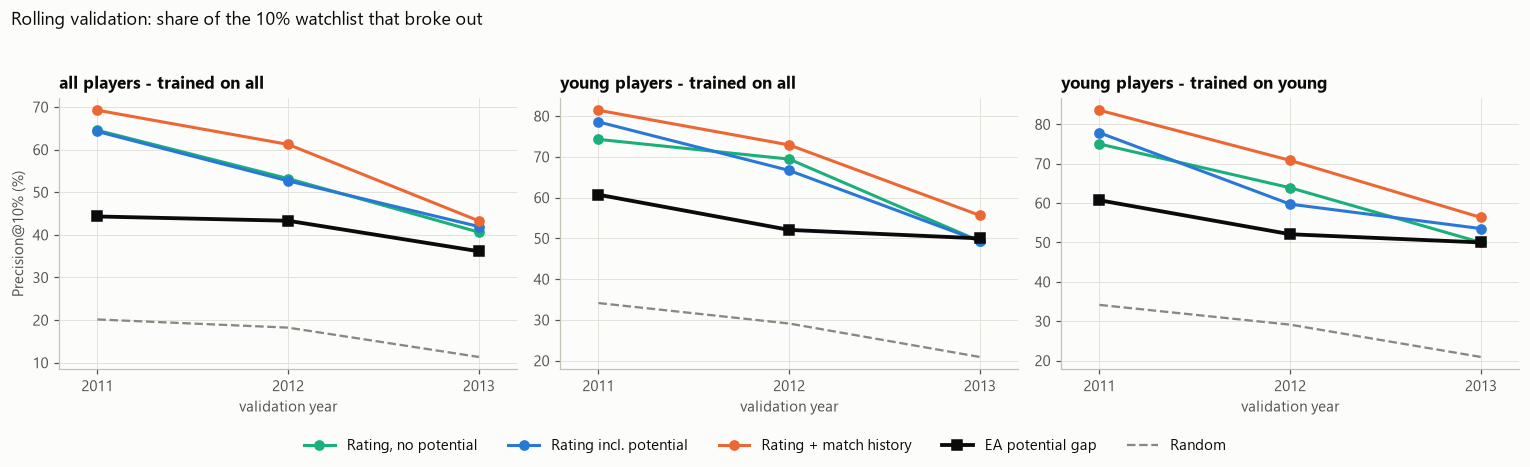

In [7]:
fig = M.plot_validation(best, summary)
save(fig, B_FIGURES, "validation_precision_by_year");

**Reading.** Every model with rating features beats the EA ranking in every validation year, and EA's ranking beats
random by a wide margin. A model fitted on `potential_gap` alone simply reproduces the EA ranking (identical
Precision@10%), which checks the pipeline. All curves fall in 2013, when the base rate dropped to 11%; the margin over
EA is also smallest in 2013, so the 2014 test may show a smaller gain than the 2011–2012 folds.

## 5. Feature-set comparisons (same model family, only the features change)

`+ potential` = rating_only − rating_no_potential; `+ match history` = combined − rating_only. Values are
Precision@10% differences in percentage points per validation year; `years_better` counts folds with a gain.

In [8]:
con = M.feature_set_contrasts(best, summary)
con.pivot_table(index=["cohort", "train_scope", "model"], columns="contrast", values="mean_pp")

contrast                          + match history  + potential  combined vs EA gap  rating w/o potential vs EA gap
cohort train_scope model                                                                                          
all    all         hist_gb                    5.1          0.2                15.5                            10.2
                   logreg                     5.0          0.2                16.7                            11.5
                   random_forest              3.5          1.2                14.5                             9.7
young  all         hist_gb                    4.4          0.5                15.0                            10.1
                   logreg                     5.6          0.5                15.7                             9.7
                   random_forest              5.6          0.0                14.3                             8.7
       young       hist_gb                    6.8          0.5                16.0                             8.7
                   logreg                     5.8          1.4                15.3                             8.0
                   random_forest              6.1          0.3                14.6                             8.2

In [9]:
con

,cohort,train_scope,model,contrast,2011,2012,2013,mean_pp,years_better
0,all,all,hist_gb,+ potential,0.6,-0.3,0.3,0.2,2
1,all,all,hist_gb,+ match history,3.9,9.4,2.1,5.1,3
2,all,all,hist_gb,rating w/o potential vs EA gap,19.1,6.7,4.7,10.2,3
3,all,all,hist_gb,combined vs EA gap,23.5,15.8,7.1,15.5,3
4,all,all,logreg,+ potential,-0.3,-0.5,1.3,0.2,1
5,all,all,logreg,+ match history,5.0,8.6,1.3,5.0,3
6,all,all,logreg,rating w/o potential vs EA gap,20.2,9.9,4.5,11.5,3
7,all,all,logreg,combined vs EA gap,24.9,17.9,7.1,16.7,3
8,all,all,random_forest,+ potential,0.3,1.9,1.6,1.2,3
9,all,all,random_forest,+ match history,3.3,7.2,0.0,3.5,2


**Reading.** (i) Adding EA's `potential` to the rating features changes the mean Precision@10% by 0 to +1.4 points —
within noise. Once a model sees the current skills, age and rating history it does not need EA's subjective potential.
This is the answer to the circularity concern: the model's edge over EA does not come from EA's potential.
(ii) **Match history adds value beyond EA's ratings**: +3.5 to +7 points of mean Precision@10% and +4 to +6.5 points of
average precision for every model family and cohort; 35 of the 36 family × fold comparisons are positive (one is zero). This is the proposal's core comparison.

## 6. Young cohort: train on all players or on young players only?

In [10]:
M.scope_contrasts(best)

,model,feature_set,mean_pp,years_better
0,hist_gb,combined,1.0,2
1,hist_gb,ea_gap_only,0.2,1
2,hist_gb,rating_no_potential,-1.4,2
3,hist_gb,rating_only,-1.4,1
4,logreg,combined,-0.4,1
5,logreg,ea_gap_only,0.0,0
6,logreg,rating_no_potential,-1.6,0
7,logreg,rating_only,-0.7,2
8,random_forest,combined,0.2,1
9,random_forest,ea_gap_only,0.0,0


**Reading.** Training on young players only is not systematically better or worse (mean differences within ±2 points,
with signs varying by year). Training on all players uses 2–3× more rows; training on young players fits the target group
directly. The selection rule picks the best candidate regardless of scope, and both scopes' predictions are delivered.

## 7. How much do the hyperparameters matter?

In [11]:
spread, class_weight = M.grid_effects(summary)
spread.query("feature_set != 'ea_gap_only'")

,cohort,train_scope,model,feature_set,min,median,max
0,all,all,hist_gb,combined,52.4,54.7,56.7
2,all,all,hist_gb,rating_no_potential,45.0,48.7,51.4
3,all,all,hist_gb,rating_only,44.5,48.9,51.6
4,all,all,logreg,combined,50.2,56.6,57.9
6,all,all,logreg,rating_no_potential,43.3,50.1,52.8
7,all,all,logreg,rating_only,43.3,50.6,53.0
8,all,all,random_forest,combined,54.8,55.3,55.8
10,all,all,random_forest,rating_no_potential,48.8,50.0,51.0
11,all,all,random_forest,rating_only,50.4,51.2,52.2
12,young,all,hist_gb,combined,64.6,67.6,69.3


In [12]:
class_weight

,cohort,train_scope,model,unweighted,weighted
0,all,all,hist_gb,48.1,48.5
1,all,all,logreg,50.8,50.5
2,all,all,random_forest,49.6,49.3
3,young,all,hist_gb,60.4,60.8
4,young,all,logreg,62.5,62.2
5,young,all,random_forest,61.4,60.6
6,young,young,hist_gb,60.2,60.5
7,young,young,logreg,61.7,61.6
8,young,young,random_forest,60.8,60.7


**Reading.** Within a family the grid moves the mean Precision@10% by 1–10 points; logistic regression is the most
sensitive (PCA on the skills and `C`), the random forest the least. Class weighting changes the mean by less than one
point: our metric only uses the *ranking* within a year, and re-weighting classes mostly shifts the predicted
probabilities rather than the order. We kept it in the grid because it is cheap and standard for imbalanced labels.

## 8. Should we train only on the most recent years?

Breakout prevalence and EA's update regime change over time, so a sliding window (last 2 years) might track the current
regime better. We re-validated each family's best setting with a 2-year window (folds 2012 and 2013; the 2011 fold
already uses exactly two years). Rule fixed in advance: adopt it only if the mean gain exceeds 1 point and more than
75% of (candidate, fold) pairs improve.

In [13]:
print(json.dumps(selected["window_check"], indent=1))

{
 "pairs": 104,
 "mean_diff_p10": -0.0096,
 "share_window_better": 0.298,
 "rule": "adopt only if mean gain > 1 pp and > 75% of (candidate, fold) pairs improve",
 "verdict": "keep expanding window (2009-2013 refit)"
}


The expanding window is kept, so the final models are refit on all of 2009–2013.

## 9. Selected models

In [14]:
rows = []
for coh, v in selected["cohorts"].items():
    p = v["primary"]
    rows.append({"cohort": coh, "train_scope": p["train_scope"], "model": p["model"], "feature_set": p["feature_set"],
                 "params": p["params"], **{f"p10_{y}": p["validation"]["precision_at_10pct_by_year"][str(y)] for y in VALIDATION_YEARS},
                 "mean_p10": p["validation"]["mean_precision_at_10pct"],
                 "ea_gap_mean_p10": v["baselines"]["ea_gap"], "random_mean_p10": v["baselines"]["random"]})
pd.DataFrame(rows)

,cohort,train_scope,model,feature_set,params,p10_2011,p10_2012,p10_2013,mean_p10,ea_gap_mean_p10,random_mean_p10
0,all,all,logreg,combined,"{'C': 0.1, 'class_weight': None, 'pca_skills': 3}",0.6925,0.6123,0.4327,0.5792,0.4126,0.1657
1,young,young,hist_gb,combined,"{'class_weight': 'balanced', 'learning_rate': ...",0.8357,0.7083,0.5634,0.7025,0.5427,0.2806


**Primary choice per cohort** follows the pre-declared rule (highest mean validation Precision@10%). The top few
candidates of each cohort are within about 2 points of each other, well inside the year-to-year sampling error, so the
family choice is not a strong finding; the feature-set result (combined > rating-only ≈ rating without potential > EA gap)
is. Workstream 4 receives test-year scores for the best setting of *every* (scope, family, feature set), so it can report
the comparison rather than only the winner.

## 10. Test-year scores written (no metrics)

In [15]:
test = pd.read_csv(PREDICTIONS / "test_predictions.csv.gz")
assert set(test.year) == {2014}
test.groupby(["cohort", "train_scope", "model"]).agg(rows=("score", "size"), feature_sets=("feature_set", "nunique"))

rows  feature_sets
cohort train_scope model                             
all    all         ea_gap          3629             1
                   hist_gb        14516             4
                   logreg         14516             4
                   random_forest  14516             4
young  all         ea_gap          1380             1
                   hist_gb         5520             4
                   logreg          5520             4
                   random_forest   5520             4
       young       ea_gap          1380             1
                   hist_gb         5520             4
                   logreg          5520             4
                   random_forest   5520             4